# NYC Shelter Intake Log: Exploratory Data Analysis

This notebook adapts the course's Week 5 Polars Lab to the NYC shelter intake CSV using PySpark to: inspect the schema, check data quality, summarize selected fields, and visualize aggregate trends. It reads directly from the provided S3 object; it does not copy the source data.

### AWS Academy Setup Note

On the terminal of the master node, run:

`
cd ~/spark
./sbin/start-master.sh --host <IP_ADDRESS>
jps
`

On the terminal of the worker nodes, run:

`
cd ~/spark
./sbin/start-worker.sh spark://<IP_ADDRESS>
jps
`

## 1. Connect to Spark and read the CSV

Spark uses the `s3a://` URI for S3 access. Schema inference is convenient for exploration but requires Spark to inspect the data; for a production pipeline, define and validate an explicit schema.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import StringType

spark = (
    SparkSession.builder
    .appName("NYC Shelter Intake EDA")
    .config("spark.jars.packages", "org.apache.hadoop:hadoop-aws:3.5.0")
    .config(
        "spark.hadoop.fs.s3a.aws.credentials.provider",
        "org.apache.hadoop.fs.s3a.AnonymousAWSCredentialsProvider",
    )
    .getOrCreate()
)

:: loading settings :: url = jar:file:/home/ubuntu/dsan6000-hw07/.venv/lib/python3.14/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/ubuntu/.ivy2.5.2/cache
The jars for the packages stored in: /home/ubuntu/.ivy2.5.2/jars
org.apache.hadoop#hadoop-aws added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-5dd93dd9-85ff-4cd7-be83-9d838dbf57a8;1.0
	confs: [default]
	found org.apache.hadoop#hadoop-aws;3.5.0 in central
	found software.amazon.awssdk#bundle;2.35.4 in central
	found software.amazon.s3.analyticsaccelerator#analyticsaccelerator-s3;1.3.1 in central
	found org.wildfly.openssl#wildfly-openssl;2.2.5.Final in central
:: resolution report :: resolve 453ms :: artifacts dl 32ms
	:: modules in use:
	org.apache.hadoop#hadoop-aws;3.5.0 from central in [default]
	org.wildfly.openssl#wildfly-openssl;2.2.5.Final from central in [default]
	software.amazon.awssdk#bundle;2.35.4 from central in

In [2]:
print("Spark:", spark.version)
print("Hadoop:", spark._jvm.org.apache.hadoop.util.VersionInfo.getVersion())
print("Master:", spark.sparkContext.master)

Spark: 4.3.0
Hadoop: 3.5.0
Master: local[*]


In [3]:
source_path = "s3a://dsan6000-final/nyc-shelters/intake_log.csv"
df = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .option("multiLine", "true")
    .csv(source_path)
)

print(f"Source: {source_path}")

SLF4J: Failed to load class "org.slf4j.impl.StaticLoggerBinder".
SLF4J: Defaulting to no-operation (NOP) logger implementation
SLF4J: See http://www.slf4j.org/codes.html#StaticLoggerBinder for further details.


Source: s3a://dsan6000-final/nyc-shelters/intake_log.csv


## 2. Inspect structure without showing records

Review the inferred column names and types.

In [4]:
df.printSchema()
print(f"Number of columns: {len(df.columns)}")
print("Columns:", df.columns)

root
 |-- intake_id: string (nullable = true)
 |-- synthetic_data: boolean (nullable = true)
 |-- client_display_name: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- household_type: string (nullable = true)
 |-- children_count: integer (nullable = true)
 |-- program_type: string (nullable = true)
 |-- contact_type: string (nullable = true)
 |-- intake_date: date (nullable = true)
 |-- presenting_reason: string (nullable = true)
 |-- prior_living_situation_reported: string (nullable = true)
 |-- reported_housing_instability_days: integer (nullable = true)
 |-- employment_status_reported: string (nullable = true)
 |-- income_status_reported: string (nullable = true)
 |-- primary_barrier: string (nullable = true)
 |-- immediate_needs: string (nullable = true)
 |-- potential_referral: string (nullable = true)
 |-- referral_status: string (nullable = true)
 |-- client_goal: string (nullable = true)
 |-- follow_up_days: integer (nullable = true)
 |-- follow_up_target_date:

### Row count

This is a full scan of the CSV. It returns only the total, not the underlying records.

In [5]:
row_count = df.count()
print(f"Number of intake records: {row_count:,}")

Number of intake records: 111,000


## 3. Create a restricted working DataFrame

Keep the original `df` available for aggregate quality checks, but use `eda_df` for later analysis. The excluded columns include identifiers, names, free text, and encoded images. 

In [6]:
sensitive_columns = [
    "intake_id",
    "client_display_name",
    "presenting_reason",
    "prior_living_situation_reported",
    "primary_barrier",
    "immediate_needs",
    "potential_referral",
    "client_goal",
    "intake_note",
    "intake_photo_b64",
]
excluded_columns = [name for name in sensitive_columns if name in df.columns]
eda_df = df.drop(*excluded_columns)
print(f"Excluded {len(excluded_columns)} sensitive or identifying columns from eda_df.")

Excluded 10 sensitive or identifying columns from eda_df.


## 4. Check missing and blank values

For string columns, whitespace-only values count as missing too. The result contains column names and aggregate counts only.

In [7]:
missing_expressions = []
for field in df.schema.fields:
    value = F.col(field.name)
    missing = value.isNull()
    if isinstance(field.dataType, StringType):
        missing = missing | (F.trim(value) == "")
    missing_expressions.append(
        F.sum(F.when(missing, 1).otherwise(0)).alias(field.name)
    )

missing_values = df.agg(*missing_expressions).first().asDict()
missingness = spark.createDataFrame(
    [(column, int(count or 0)) for column, count in missing_values.items()],
    ["column", "missing_count"],
).withColumn("missing_pct", F.round(F.col("missing_count") / F.lit(row_count) * 100, 2))

missingness.orderBy(F.desc("missing_pct"), F.asc("column")).show(
    n=len(df.columns), truncate=False
)

26/11/18 17:05:49 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+---------------------------------+-------------+-----------+
|column                           |missing_count|missing_pct|
+---------------------------------+-------------+-----------+
|age                              |0            |0.0        |
|children_count                   |0            |0.0        |
|client_display_name              |0            |0.0        |
|client_goal                      |0            |0.0        |
|contact_type                     |0            |0.0        |
|employment_status_reported       |0            |0.0        |
|follow_up_days                   |0            |0.0        |
|follow_up_target_date            |0            |0.0        |
|household_type                   |0            |0.0        |
|housing_eligibility_verified     |0            |0.0        |
|immediate_needs                  |0            |0.0        |
|income_status_reported           |0            |0.0        |
|intake_date                      |0            |0.0        |
|intake_

## 5. Check the synthetic-data marker and duplicate IDs

These checks report counts only.

In [8]:
if "synthetic_data" in df.columns:
    df.groupBy("synthetic_data").count().orderBy("synthetic_data").show()

if "intake_id" in df.columns:
    duplicate_id_groups = (
        df.groupBy("intake_id")
        .count()
        .filter(F.col("count") > 1)
        .count()
    )
    print(f"Number of intake IDs appearing more than once: {duplicate_id_groups:,}")

+--------------+------+
|synthetic_data| count|
+--------------+------+
|          true|111000|
+--------------+------+



Number of intake IDs appearing more than once: 0


## 6. Summarize numeric fields

Approximate quartiles give a robust first look at numeric distributions without collecting individual values. Only the aggregate quantiles are brought back to the notebook driver.

In [9]:
numeric_candidates = [
    "age",
    "children_count",
    "reported_housing_instability_days",
    "follow_up_days",
    "note_word_count",
]
numeric_columns = [name for name in numeric_candidates if name in eda_df.columns]

if numeric_columns:
    quantiles = eda_df.approxQuantile(numeric_columns, [0.25, 0.5, 0.75], 0.01)
    for name, values in zip(numeric_columns, quantiles):
        print(f"{name} (25th, 50th, 75th percentiles): {values}")
else:
    print("No expected numeric columns were found. Check the inferred schema.")

age (25th, 50th, 75th percentiles): [30.0, 41.0, 54.0]
children_count (25th, 50th, 75th percentiles): [0.0, 0.0, 0.0]
reported_housing_instability_days (25th, 50th, 75th percentiles): [45.0, 86.0, 129.0]
follow_up_days (25th, 50th, 75th percentiles): [2.0, 5.0, 5.0]
note_word_count (25th, 50th, 75th percentiles): [262.0, 264.0, 267.0]


## 7. Explore selected categorical fields

These are intended to be categorical fields from the codebook. Rare categories are suppressed with a minimum count of five.

In [10]:
categorical_columns = [
    "household_type",
    "program_type",
    "contact_type",
    "employment_status_reported",
    "income_status_reported",
    "referral_status",
    "housing_eligibility_verified",
]
categorical_columns = [name for name in categorical_columns if name in eda_df.columns]

for name in categorical_columns:
    print(f"\n{name}: top categories (groups with fewer than 5 records omitted)")
    (
        eda_df.groupBy(name)
        .count()
        .filter(F.col("count") >= 5)
        .orderBy(F.desc("count"))
        .limit(20)
        .show(truncate=True)
    )


household_type: top categories (groups with fewer than 5 records omitted)


+--------------------+-----+
|      household_type|count|
+--------------------+-----+
|        Single adult|77700|
|Family with children|22200|
|         Young adult|11100|
+--------------------+-----+


program_type: top categories (groups with fewer than 5 records omitted)


+-----------------+------+
|     program_type| count|
+-----------------+------+
|Emergency Shelter|111000|
+-----------------+------+


contact_type: top categories (groups with fewer than 5 records omitted)


+--------------+------+
|  contact_type| count|
+--------------+------+
|Initial Intake|111000|
+--------------+------+


employment_status_reported: top categories (groups with fewer than 5 records omitted)


+--------------------------+-----+
|employment_status_reported|count|
+--------------------------+-----+
|      Not currently wor...|28031|
|      Temporary employment|27813|
|                Unemployed|27786|
|      Part-time employment|27370|
+--------------------------+-----+


income_status_reported: top categories (groups with fewer than 5 records omitted)


+----------------------+-----+
|income_status_reported|count|
+----------------------+-----+
|  Public benefits r...|27903|
|      Irregular income|27869|
|    No income reported|27687|
|  Limited earned in...|27541|
+----------------------+-----+


referral_status: top categories (groups with fewer than 5 records omitted)


+--------------------+------+
|     referral_status| count|
+--------------------+------+
|Discussed, not co...|111000|
+--------------------+------+


housing_eligibility_verified: top categories (groups with fewer than 5 records omitted)


+----------------------------+------+
|housing_eligibility_verified| count|
+----------------------------+------+
|                       false|111000|
+----------------------------+------+



## 8. Parse intake dates and check date quality

The conversion below expects Spark-recognized date strings (commonly `yyyy-MM-dd`). First inspect the parse-success counts; if the source uses another format, pass that format as the second argument to `to_date`.

In [11]:
if "intake_date" in df.columns:
    dated_df = df.withColumn(
        "_intake_date_parsed",
        F.to_date(F.col("intake_date").cast("string")),
    )
    date_quality = dated_df.agg(
        F.count("_intake_date_parsed").alias("parsed_dates"),
        F.sum(F.col("_intake_date_parsed").isNull().cast("long")).alias("missing_or_unparsed"),
        F.min("_intake_date_parsed").alias("earliest_date"),
        F.max("_intake_date_parsed").alias("latest_date"),
    )
    date_quality.show(truncate=False)
else:
    print("intake_date was not found. Check the schema and codebook.")

+------------+-------------------+-------------+-----------+
|parsed_dates|missing_or_unparsed|earliest_date|latest_date|
+------------+-------------------+-------------+-----------+
|111000      |0                  |2026-02-14   |2026-11-11 |
+------------+-------------------+-------------+-----------+



### Intakes by month

The chart is based on monthly aggregate counts, not individual records.

In [13]:
!pip install matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 79.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 64.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 100.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 128.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [seaborn]m7/8 [seaborn]ib]


+-------+-----+
|month  |count|
+-------+-----+
|2026-02|6306 |
|2026-03|12640|
|2026-04|12255|
|2026-05|13003|
|2026-06|12137|
|2026-07|12629|
|2026-08|12669|
|2026-09|12254|
|2026-10|12539|
|2026-11|4568 |
+-------+-----+



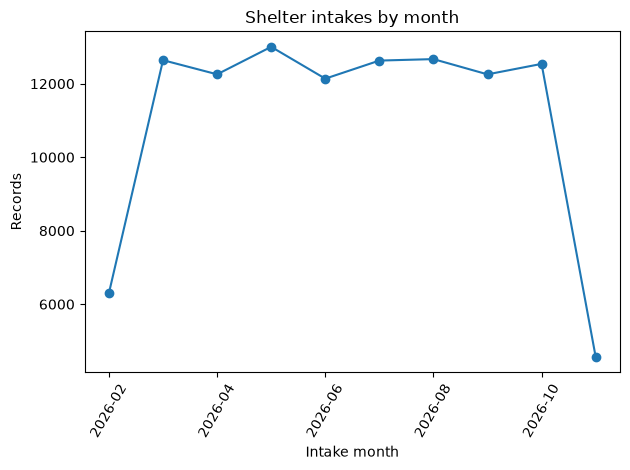

In [14]:
if "intake_date" in df.columns:
    monthly_intakes = (
        dated_df.filter(F.col("_intake_date_parsed").isNotNull())
        .groupBy(F.date_format("_intake_date_parsed", "yyyy-MM").alias("month"))
        .count()
        .orderBy("month")
    )
    monthly_intakes.show(n=120, truncate=False)

    monthly_pdf = monthly_intakes.limit(120).toPandas()
    if not monthly_pdf.empty:
        import matplotlib.pyplot as plt

        ax = monthly_pdf.plot(x="month", y="count", kind="line", marker="o", legend=False)
        ax.set(title="Shelter intakes by month", xlabel="Intake month", ylabel="Records")
        ax.tick_params(axis="x", labelrotation=60)
        plt.tight_layout()
        plt.show()

## 9. Follow-up timing

Compare the intake date with the follow-up target date. The output is aggregated; it does not expose the dates or other fields for individual clients.

In [15]:
if "intake_date" in df.columns and "follow_up_target_date" in df.columns:
    follow_up_df = (
        df.withColumn("_intake_date", F.to_date(F.col("intake_date").cast("string")))
        .withColumn(
            "_target_date",
            F.to_date(F.col("follow_up_target_date").cast("string")),
        )
        .withColumn("_days_to_target", F.datediff("_target_date", "_intake_date"))
    )
    follow_up_df.agg(
        F.count("_days_to_target").alias("records_with_both_dates"),
        F.avg("_days_to_target").alias("mean_days_to_target"),
        F.expr("percentile_approx(_days_to_target, 0.5)").alias("median_days_to_target"),
        F.sum((F.col("_days_to_target") < 0).cast("long")).alias("negative_intervals"),
    ).show(truncate=False)
else:
    print("One or both follow-up date fields were not found.")

+-----------------------+-------------------+---------------------+------------------+
|records_with_both_dates|mean_days_to_target|median_days_to_target|negative_intervals|
+-----------------------+-------------------+---------------------+------------------+
|111000                 |4.250405405405405  |5                    |0                 |
+-----------------------+-------------------+---------------------+------------------+



## 10. Compare selected categories

A grouped count can help identify patterns worth investigating. The minimum group size filter reduces the chance of exposing rare cases.

In [16]:
if "program_type" in eda_df.columns and "referral_status" in eda_df.columns:
    (
        eda_df.groupBy("program_type", "referral_status")
        .count()
        .filter(F.col("count") >= 5)
        .orderBy(F.desc("count"))
        .show(n=50, truncate=True)
    )
else:
    print("program_type or referral_status was not found.")

+-----------------+--------------------+------+
|     program_type|     referral_status| count|
+-----------------+--------------------+------+
|Emergency Shelter|Discussed, not co...|111000|
+-----------------+--------------------+------+



## 11. Questions to take forward

- Are intake volumes changing over time, and are there gaps in date coverage?
- Which categories have the most missing data?
- How do follow-up target intervals vary, and how many records have a negative interval?
- Do the category patterns persist after checking for missing values and small group sizes?